# Segmentación de clientes con K-Means

**Objetivo general:** desarrollar un modelo de segmentación de clientes con K-Means, evaluado con el método del codo y el coeficiente de silueta, para analizar patrones de comportamiento y apoyar decisiones de marketing.

**Dataset:** `Mall_Customers.xls` – *Mall Customers* (200 clientes de un centro comercial): `CustomerID`, `Gender` (género), `Age`, `Annual Income (k$)` y `Spending Score (1-100)`.

Estructura del cuaderno:
1. Exploración de datos
2. Preprocesamiento
3. Método del codo
4. Coeficiente de silueta
5. Modelo K-Means
6. Interpretación de negocio
7. Despliegue con Streamlit (archivo `app.py`)

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

---
## Parte 1 – Exploración de datos

### 1.1 Cargar el dataset

In [2]:
# El archivo tiene extensión .xls pero su contenido es texto separado por comas (CSV),
# por eso se intenta primero read_excel y, si falla, read_csv.
RUTA = "Mall_Customers.xls"
try:
    df = pd.read_excel(RUTA)
except Exception:
    df = pd.read_csv(RUTA)

df = df.rename(columns={
    "Gender": "Genero", "Genre": "Genero",
    "Age": "Edad",
    "Annual Income (k$)": "Ingreso_Anual_k",
    "Spending Score (1-100)": "Puntaje_Gasto",
})
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (200, 5)


,CustomerID,Genero,Edad,Ingreso_Anual_k,Puntaje_Gasto
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 1.2 Identificar variables relevantes

In [3]:
df.info()
print("\nValores nulos por columna:\n", df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   CustomerID       200 non-null    int64
 1   Genero           200 non-null    str  
 2   Edad             200 non-null    int64
 3   Ingreso_Anual_k  200 non-null    int64
 4   Puntaje_Gasto    200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Valores nulos por columna:
 CustomerID         0
Genero             0
Edad               0
Ingreso_Anual_k    0
Puntaje_Gasto      0
dtype: int64

Filas duplicadas: 0


| Variable | Tipo | ¿Útil para segmentar? |
|---|---|---|
| `CustomerID` | Identificador | No: es solo un código, no describe comportamiento |
| `Genero` | Categórica | Poco: K-Means trabaja con distancias euclidianas y no maneja bien variables binarias |
| `Edad` | Numérica | Sí, describe el perfil demográfico |
| `Ingreso_Anual_k` | Numérica | Sí, mide capacidad de compra |
| `Puntaje_Gasto` | Numérica | Sí, mide comportamiento de compra |

### 1.3 Análisis descriptivo básico

In [4]:
df.drop(columns="CustomerID").describe(include="all").round(2)

,Genero,Edad,Ingreso_Anual_k,Puntaje_Gasto
count,200,200.00,200.00,200.00
unique,2,NaN,NaN,NaN
top,Female,NaN,NaN,NaN
freq,112,NaN,NaN,NaN
mean,NaN,38.85,60.56,50.20
std,NaN,13.97,26.26,25.82
min,NaN,18.00,15.00,1.00
25%,NaN,28.75,41.50,34.75
50%,NaN,36.00,61.50,50.00
75%,NaN,49.00,78.00,73.00


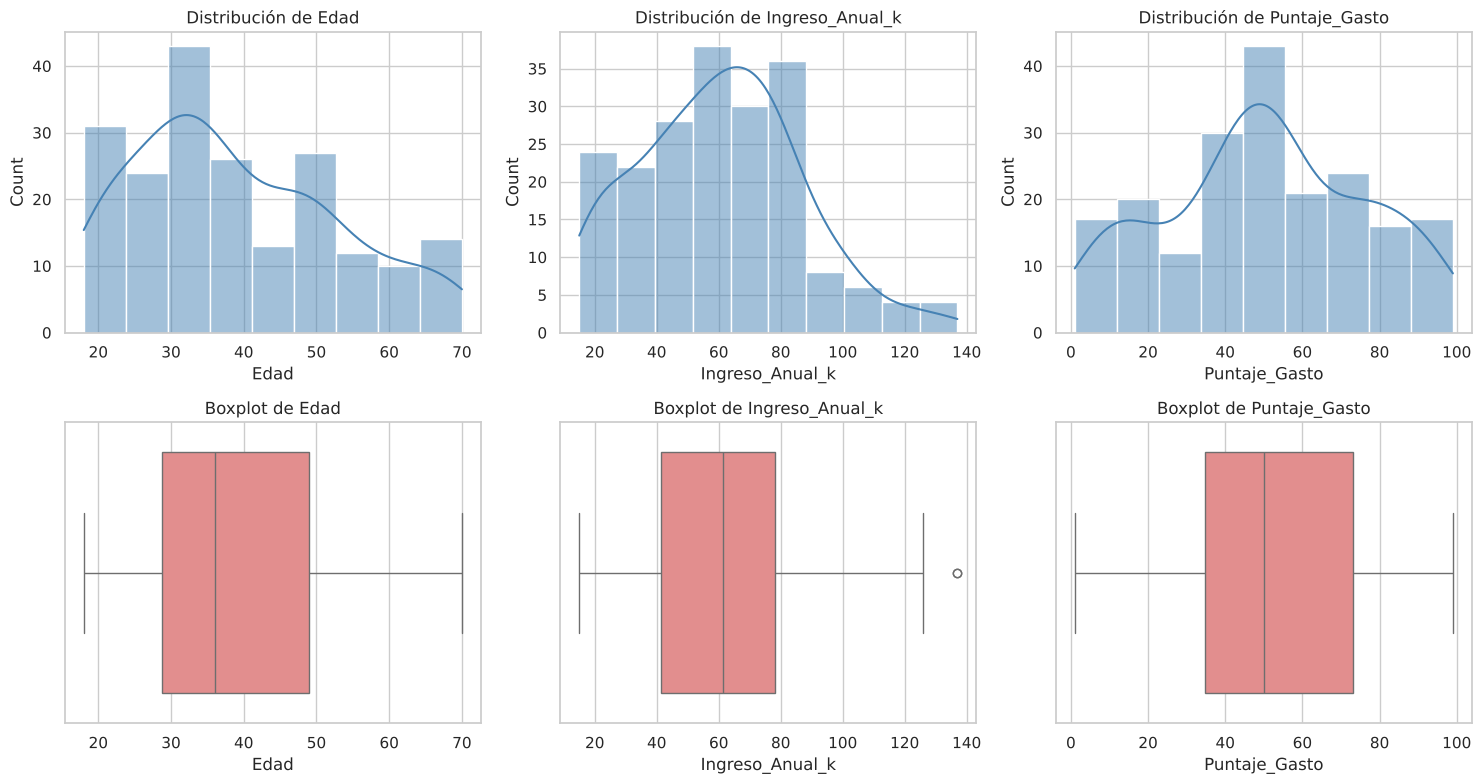

In [5]:
num = ["Edad", "Ingreso_Anual_k", "Puntaje_Gasto"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"Distribución de {col}")
    sns.boxplot(x=df[col], ax=axes[1, i], color="lightcoral")
    axes[1, i].set_title(f"Boxplot de {col}")
plt.tight_layout(); plt.show()

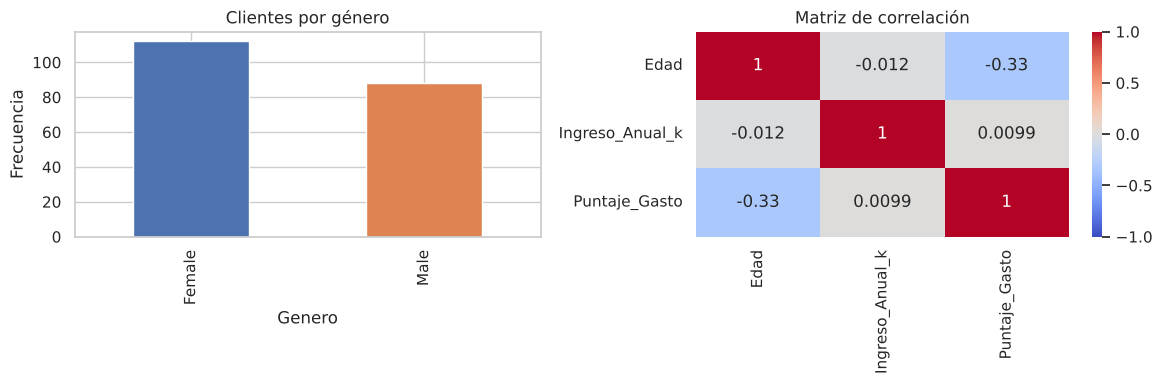

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Genero"].value_counts().plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Clientes por género"); axes[0].set_ylabel("Frecuencia")
sns.heatmap(df[num].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Matriz de correlación")
plt.tight_layout(); plt.show()

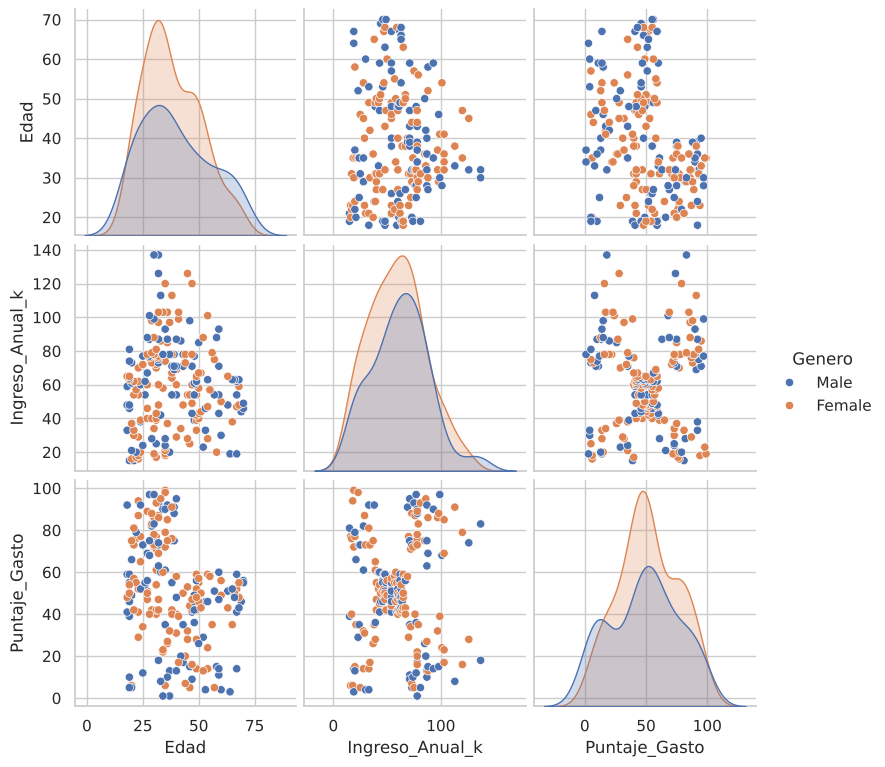

In [7]:
sns.pairplot(df, vars=num, hue="Genero", diag_kind="kde", height=2.6)
plt.show()

In [8]:
# Detección de valores atípicos con la regla del rango intercuartílico (IQR)
def atipicos_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]

for col in num:
    out = atipicos_iqr(df[col])
    print(f"{col}: {len(out)} atípicos -> {out.tolist()}")

Edad: 0 atípicos -> []
Ingreso_Anual_k: 2 atípicos -> [137, 137]
Puntaje_Gasto: 0 atípicos -> []


### Preguntas – Parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**

`Ingreso_Anual_k` y `Puntaje_Gasto`. Juntas describen *cuánto puede gastar* el cliente y *cuánto gasta realmente*, que es exactamente lo que interesa en marketing. Además, su diagrama de dispersión muestra grupos visibles a simple vista (forma de "X" con un centro denso), lo que hace que K-Means funcione muy bien. La `Edad` aporta contexto y se usará para describir los clusters, pero no se incluye en el entrenamiento para que los segmentos sean fáciles de interpretar y graficar en 2D. `CustomerID` se descarta por ser un identificador y `Genero` porque es categórica y apenas cambia la distribución del resto de variables.

**¿Se identifican valores atípicos?**

Muy pocos. Según la regla IQR solo hay 2 clientes con ingreso de 137 k$ (por encima del límite superior de ≈132 k$). `Edad` y `Puntaje_Gasto` no tienen atípicos. Esos 2 valores son plausibles (clientes de ingresos muy altos), no errores, así que se conservan: eliminarlos haría perder justamente a clientes valiosos. Tampoco hay valores nulos ni filas duplicadas.

**¿Qué tipo de relaciones se observan entre las variables?**

- **Ingreso vs. gasto:** correlación lineal prácticamente nula (r ≈ 0.01), pero sí hay una relación **no lineal por grupos**: se forman unas 5 nubes (ingreso bajo/alto combinado con gasto bajo/alto, más un grupo central). Que ganar más no implique gastar más es lo que hace interesante segmentar.
- **Edad vs. gasto:** correlación negativa moderada (r ≈ −0.33): los clientes jóvenes tienden a tener puntajes de gasto más altos; los mayores de ~40 años rara vez superan 60 puntos.
- **Edad vs. ingreso:** sin relación (r ≈ −0.01).
- **Género:** las distribuciones de hombres y mujeres son muy parecidas (hay algo más de mujeres, 112 vs. 88).

---
## Parte 2 – Preprocesamiento

Se seleccionan las variables de segmentación y se normalizan con `StandardScaler`, que transforma cada variable a media 0 y desviación estándar 1:  $z = (x - \mu)/\sigma$.

In [9]:
FEATURES = ["Ingreso_Anual_k", "Puntaje_Gasto"]
X = df[FEATURES].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame({
    "Media original": X.mean(axis=0), "Desv. original": X.std(axis=0),
    "Media escalada": X_scaled.mean(axis=0).round(4), "Desv. escalada": X_scaled.std(axis=0).round(4),
}, index=FEATURES)

,Media original,Desv. original,Media escalada,Desv. escalada
Ingreso_Anual_k,60.56,26.198977,-0.0,1.0
Puntaje_Gasto,50.20,25.758882,-0.0,1.0


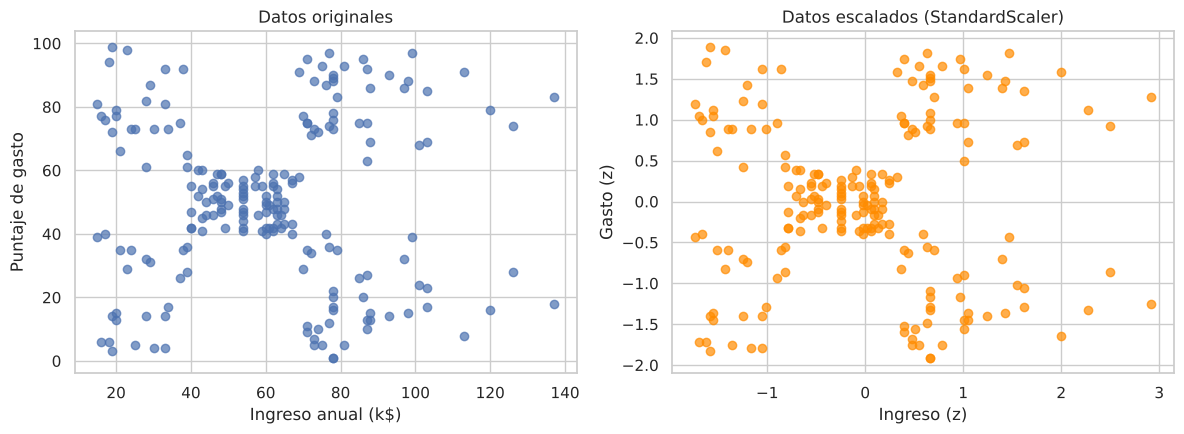

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X[:, 0], X[:, 1], alpha=.7)
axes[0].set(title="Datos originales", xlabel="Ingreso anual (k$)", ylabel="Puntaje de gasto")
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], alpha=.7, color="darkorange")
axes[1].set(title="Datos escalados (StandardScaler)", xlabel="Ingreso (z)", ylabel="Gasto (z)")
plt.tight_layout(); plt.show()

### Pregunta – Parte 2

**¿Por qué es necesario escalar las variables en el algoritmo K-Means?**

K-Means asigna cada punto al centroide más cercano según la **distancia euclidiana**, $d = \sqrt{\sum (x_i - c_i)^2}$. Si una variable tiene un rango numérico mayor (por ejemplo, ingresos en dólares que van de miles a cientos de miles frente a una edad de 18 a 70), sus diferencias dominan la suma y el algoritmo prácticamente ignora las demás variables: los clusters quedarían definidos por la unidad de medida y no por el comportamiento real del cliente.

Al estandarizar, todas las variables quedan en la misma escala (media 0, desviación 1) y **contribuyen por igual a la distancia**. Además, la inercia (WCSS) y la silueta pasan a ser comparables y la convergencia es más estable. En este dataset las dos variables tienen rangos parecidos, pero escalar sigue siendo buena práctica y es imprescindible si se agregan variables como la edad o un ingreso expresado en pesos.

Importante: el mismo `scaler` ajustado aquí se guarda y se reutiliza para transformar a los clientes nuevos en la aplicación.

---
## Parte 3 – Método del codo

Se entrena K-Means para K = 1…10 y se registra la **inercia** o WCSS (*Within-Cluster Sum of Squares*): la suma de las distancias al cuadrado de cada punto a su centroide.

$$WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

In [11]:
K_RANGE = range(1, 11)
inercias = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

tabla_codo = pd.DataFrame({"K": list(K_RANGE), "Inercia (WCSS)": np.round(inercias, 2)})
tabla_codo["Reducción %"] = (-tabla_codo["Inercia (WCSS)"].pct_change() * 100).round(1)
tabla_codo

,K,Inercia (WCSS),Reducción %
0,1,400.00,NaN
1,2,269.69,32.6
2,3,157.70,41.5
3,4,108.92,30.9
4,5,65.57,39.8
5,6,55.06,16.0
6,7,44.86,18.5
7,8,37.23,17.0
8,9,32.39,13.0
9,10,29.98,7.4


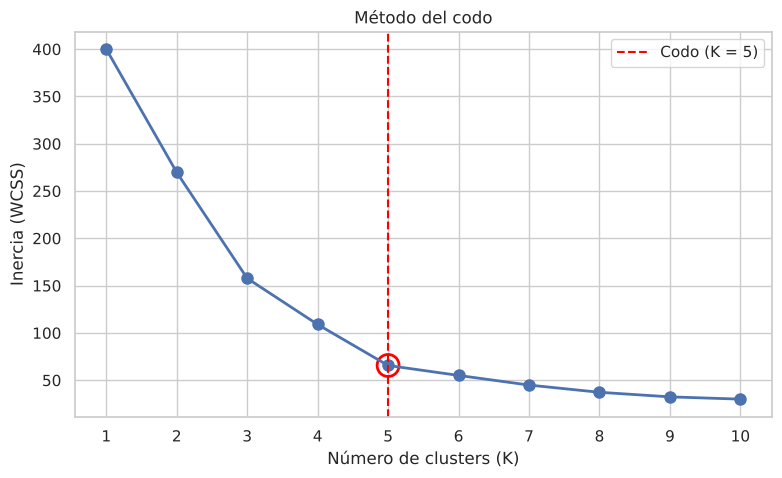

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(list(K_RANGE), inercias, "o-", linewidth=2, markersize=8)
plt.axvline(5, color="red", linestyle="--", label="Codo (K = 5)")
plt.scatter(5, inercias[4], s=250, facecolors="none", edgecolors="red", linewidths=2)
plt.title("Método del codo")
plt.xlabel("Número de clusters (K)"); plt.ylabel("Inercia (WCSS)")
plt.xticks(list(K_RANGE)); plt.legend(); plt.show()

### Preguntas – Parte 3

**¿Por qué valores cercanos a cero indican mejor ajuste?**

La inercia suma las distancias al cuadrado entre cada cliente y el centroide de su grupo. Un valor cercano a cero significa que los puntos están muy pegados a su centroide: los clusters son **compactos y homogéneos**, y el centroide representa bien a cada miembro del grupo. Una inercia alta indica grupos dispersos donde el centroide resume mal a sus clientes.

Matiz importante: la inercia **siempre disminuye** al aumentar K y llega a 0 cuando K = n (cada cliente es su propio cluster), lo cual no sirve para el negocio. Por eso no se busca la inercia mínima absoluta, sino el punto donde agregar más clusters deja de reducirla de forma significativa.

**¿Cómo se identifica el punto óptimo de K?**

Se busca el **"codo"** de la curva: el valor de K a partir del cual la pendiente se suaviza y las reducciones adicionales de inercia son marginales. En la tabla se ve que la inercia baja fuertemente hasta K = 5 (de 400 a ≈66; pasar de 4 a 5 aún reduce ≈40 %), y desde K = 6 cada cluster extra solo reduce entre 10 % y 17 %. Por lo tanto el codo está en **K = 5**. Como la lectura del codo es algo subjetiva, se confirma con el coeficiente de silueta.

---
## Parte 4 – Coeficiente de silueta

Para cada punto $i$: $a(i)$ = distancia media a los puntos de su propio cluster; $b(i)$ = distancia media al cluster vecino más cercano.

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}} \in [-1, 1]$$

El coeficiente global es el promedio de $s(i)$. Requiere K ≥ 2.

In [13]:
K_SIL = range(2, 11)
siluetas = []
for k in K_SIL:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    etiquetas = km.fit_predict(X_scaled)
    siluetas.append(silhouette_score(X_scaled, etiquetas))

tabla_sil = pd.DataFrame({"K": list(K_SIL), "Silueta": np.round(siluetas, 4)})
k_opt = int(tabla_sil.loc[tabla_sil["Silueta"].idxmax(), "K"])
print("K con mayor silueta:", k_opt)
tabla_sil

K con mayor silueta: 5


,K,Silueta
0,2,0.3213
1,3,0.4666
2,4,0.4939
3,5,0.5547
4,6,0.5399
5,7,0.5281
6,8,0.4552
7,9,0.4571
8,10,0.4432


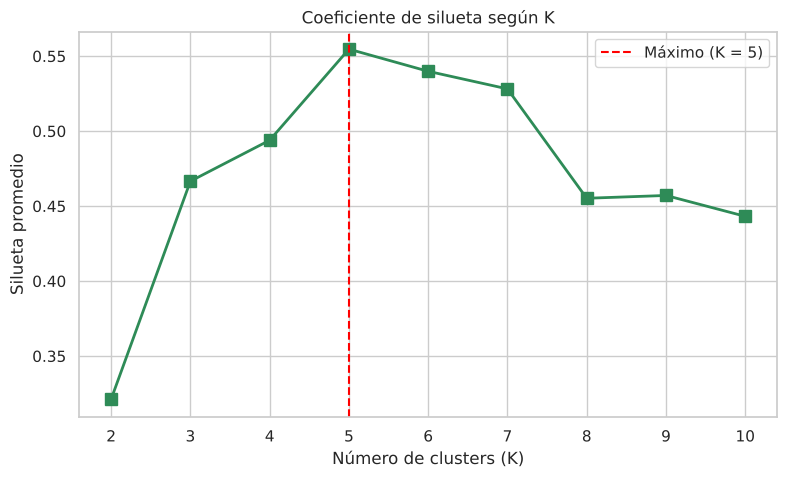

In [14]:
plt.figure(figsize=(9, 5))
plt.plot(list(K_SIL), siluetas, "s-", color="seagreen", linewidth=2, markersize=8)
plt.axvline(k_opt, color="red", linestyle="--", label=f"Máximo (K = {k_opt})")
plt.title("Coeficiente de silueta según K")
plt.xlabel("Número de clusters (K)"); plt.ylabel("Silueta promedio")
plt.xticks(list(K_SIL)); plt.legend(); plt.show()

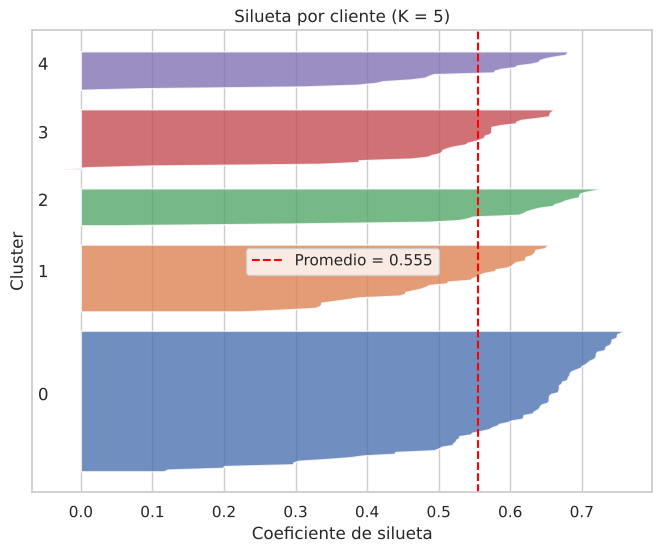

Clientes con silueta negativa: 2


In [15]:
# Gráfico de silueta por observación para el K elegido
km_tmp = KMeans(n_clusters=k_opt, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
s_vals = silhouette_samples(X_scaled, km_tmp.labels_)
fig, ax = plt.subplots(figsize=(8, 6)); y = 10
for c in range(k_opt):
    v = np.sort(s_vals[km_tmp.labels_ == c])
    ax.fill_betweenx(np.arange(y, y + len(v)), 0, v, alpha=.8)
    ax.text(-0.06, y + len(v) / 2, str(c)); y += len(v) + 10
ax.axvline(s_vals.mean(), color="red", linestyle="--", label=f"Promedio = {s_vals.mean():.3f}")
ax.set(title=f"Silueta por cliente (K = {k_opt})", xlabel="Coeficiente de silueta", ylabel="Cluster", yticks=[])
ax.legend(); plt.show()
print("Clientes con silueta negativa:", (s_vals < 0).sum())

### Preguntas – Parte 4

**¿Qué mide el coeficiente de silueta?**

Mide qué tan bien asignado está cada punto comparando dos cosas a la vez: la **cohesión** (qué tan cerca está de los miembros de su propio cluster, $a$) y la **separación** (qué tan lejos está del cluster vecino más cercano, $b$). A diferencia de la inercia, no mejora automáticamente al aumentar K, por lo que sirve para elegir el número de clusters.

**¿Qué significa un valor cercano a 1?**

Que el punto está mucho más cerca de su propio grupo que del vecino ($a \ll b$): está bien asignado y los clusters son compactos y bien separados. Un promedio cercano a 1 indica una estructura de grupos muy clara.

**¿Qué implica un valor cercano a 0 o negativo?**

- **≈ 0:** el punto está en la frontera entre dos clusters ($a \approx b$); los grupos se solapan y la asignación es ambigua.
- **Negativo:** el punto está más cerca, en promedio, de otro cluster que del suyo ($a > b$): probablemente está mal asignado, o el valor de K no es adecuado. Muchos negativos indican una mala segmentación.

**¿Coincide el valor óptimo de K con el método del codo? Justifique.**

Sí. La silueta alcanza su máximo en **K = 5 (≈ 0.555)**, justo donde está el codo de la inercia. Las dos métricas miran cosas distintas (la inercia solo cohesión; la silueta, cohesión y separación) y llegan a la misma conclusión, lo que da robustez a la elección. Con K = 6 la silueta baja (≈ 0.540) porque se parte un grupo natural en dos, y con K = 4 dos grupos distintos quedan fusionados. Un valor de 0.55 indica una estructura razonablemente fuerte (> 0.5), y el gráfico por cliente muestra prácticamente ningún punto con silueta negativa. Coincide también con la inspección visual: en el diagrama de dispersión se distinguen 5 nubes.

---
## Parte 5 – Modelo K-Means

Se entrena el modelo final con K = 5.

In [16]:
K_FINAL = 5
kmeans = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=10, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print(f"Inercia: {kmeans.inertia_:.2f}")
print(f"Silueta: {silhouette_score(X_scaled, df['Cluster']):.4f}")
df["Cluster"].value_counts().sort_index().rename("N.º clientes").to_frame()

Inercia: 65.57
Silueta: 0.5547


,N.º clientes
Cluster,
0,81
1,39
2,22
3,35
4,23


In [17]:
# Centroides en escala estandarizada y en escala original
centroides_esc = pd.DataFrame(kmeans.cluster_centers_, columns=[f + " (z)" for f in FEATURES])
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES).round(1)
centroides.index.name = "Cluster"
pd.concat([centroides, centroides_esc.round(2)], axis=1)

,Ingreso_Anual_k,Puntaje_Gasto,Ingreso_Anual_k (z),Puntaje_Gasto (z)
0,55.3,49.5,-0.20,-0.03
1,86.5,82.1,0.99,1.24
2,25.7,79.4,-1.33,1.13
3,88.2,17.1,1.06,-1.28
4,26.3,20.9,-1.31,-1.14


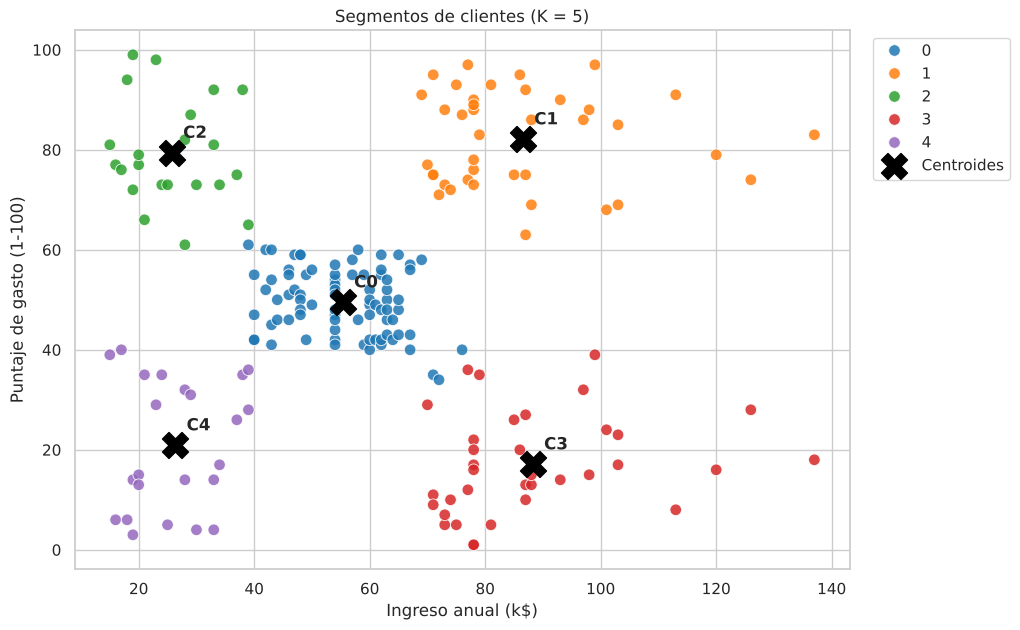

In [18]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x="Ingreso_Anual_k", y="Puntaje_Gasto", hue="Cluster",
                palette="tab10", s=70, alpha=.85)
plt.scatter(centroides["Ingreso_Anual_k"], centroides["Puntaje_Gasto"], s=350, c="black",
            marker="X", label="Centroides")
for c, fila in centroides.iterrows():
    plt.annotate(f"C{c}", (fila.iloc[0] + 2, fila.iloc[1] + 3), fontsize=12, weight="bold")
plt.title(f"Segmentos de clientes (K = {K_FINAL})")
plt.xlabel("Ingreso anual (k$)"); plt.ylabel("Puntaje de gasto (1-100)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

In [19]:
resumen = df.groupby("Cluster").agg(
    Clientes=("CustomerID", "count"),
    Edad_media=("Edad", "mean"),
    Ingreso_medio=("Ingreso_Anual_k", "mean"),
    Gasto_medio=("Puntaje_Gasto", "mean"),
    Pct_mujeres=("Genero", lambda g: (g == "Female").mean() * 100),
).round(1)
resumen["% del total"] = (resumen["Clientes"] / len(df) * 100).round(1)
resumen

,Clientes,Edad_media,Ingreso_medio,Gasto_medio,Pct_mujeres,% del total
Cluster,,,,,,
0,81,42.7,55.3,49.5,59.3,40.5
1,39,32.7,86.5,82.1,53.8,19.5
2,22,25.3,25.7,79.4,59.1,11.0
3,35,41.1,88.2,17.1,45.7,17.5
4,23,45.2,26.3,20.9,60.9,11.5


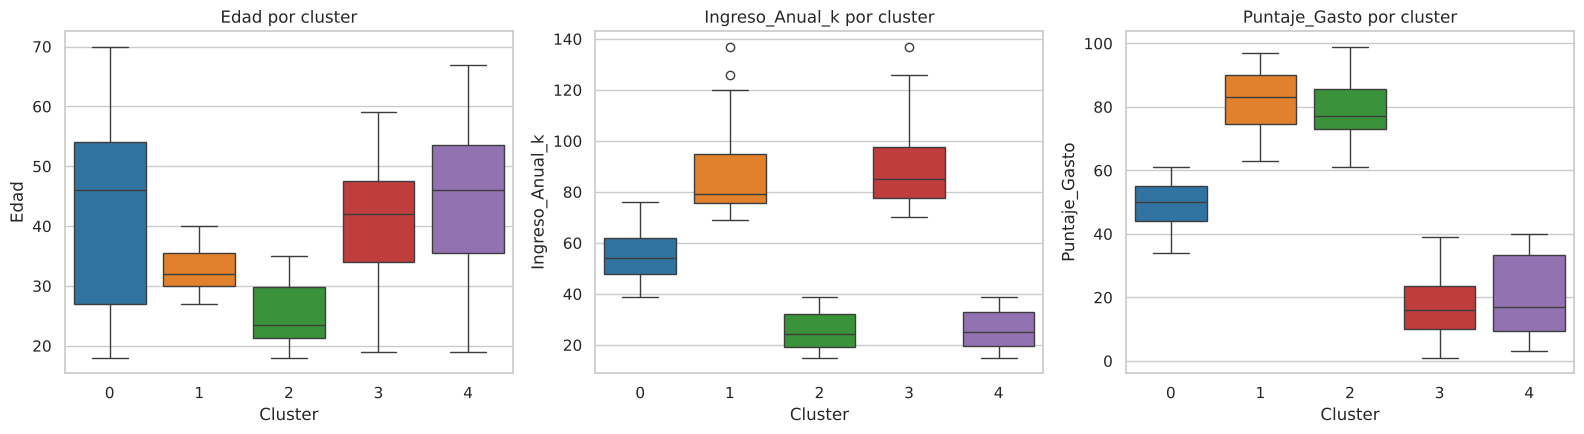

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, num):
    sns.boxplot(data=df, x="Cluster", y=col, palette="tab10", ax=ax)
    ax.set_title(f"{col} por cluster")
plt.tight_layout(); plt.show()

### Preguntas – Parte 5

**¿Qué representa cada cluster?**

Cada cluster es un grupo de clientes con un comportamiento similar en ingreso y gasto, y su **centroide** es el "cliente típico" del grupo (el promedio de sus miembros). Leyendo los centroides en escala original (los números de cluster pueden variar según la versión de scikit-learn; la descripción se basa en los valores):

| Centroide (ingreso, gasto) | Descripción | Tamaño aprox. |
|---|---|---|
| ≈ (87 k$, 82) | Ingreso alto y gasto alto; edad media ≈ 33 años | 39 (19.5 %) |
| ≈ (55 k$, 50) | Ingreso y gasto medios; el grupo más grande, edad ≈ 43 | 81 (40.5 %) |
| ≈ (26 k$, 79) | Ingreso bajo pero gasto alto; los más jóvenes (≈ 25 años) | 22 (11 %) |
| ≈ (88 k$, 17) | Ingreso alto pero gasto bajo; edad ≈ 41 | 35 (17.5 %) |
| ≈ (26 k$, 21) | Ingreso bajo y gasto bajo; los de mayor edad (≈ 45) | 23 (11.5 %) |

**¿Qué diferencias existen entre los grupos obtenidos?**

- **El ingreso no determina el gasto:** hay dos grupos de ingreso alto (~87 k$) con comportamientos opuestos (gasto 82 vs. 17), y dos grupos de ingreso bajo (~26 k$) también opuestos (79 vs. 21). La diferencia está en la *disposición* a gastar, no en la capacidad.
- **La edad acompaña al gasto:** los grupos de gasto alto son los más jóvenes (25–33 años) y los de gasto bajo los mayores (41–45 años), lo que confirma la correlación negativa observada en la Parte 1 aunque la edad no se usó para entrenar.
- **Tamaño:** el segmento medio concentra 4 de cada 10 clientes; los extremos tienen entre 22 y 39 clientes.
- **Dispersión:** el grupo medio es el más compacto; los grupos de ingreso alto son más dispersos en ingreso (incluyen los valores de 137 k$).
- **Género:** la proporción de mujeres es similar en todos (≈ 50–60 %), por lo que el género no diferencia los segmentos.

---
## Parte 6 – Interpretación de negocio

Los perfiles se asignan con reglas sobre los centroides (y no con el número del cluster), para que el resultado no dependa de cómo K-Means numeró los grupos.

In [21]:
ing_med, gas_med = df["Ingreso_Anual_k"].median(), df["Puntaje_Gasto"].median()

def asignar_perfil(ingreso, gasto, banda=12):
    """Clasifica un centroide según su posición respecto a las medianas."""
    if abs(ingreso - ing_med) <= banda and abs(gasto - gas_med) <= banda:
        return "Clientes promedio"
    if ingreso >= ing_med and gasto >= gas_med:
        return "Clientes de alto valor"
    if ingreso >= ing_med and gasto < gas_med:
        return "Clientes con potencial"
    if ingreso < ing_med and gasto >= gas_med:
        return "Clientes promedio – gastadores jóvenes"
    return "Clientes de bajo valor"

PERFILES = {c: asignar_perfil(f["Ingreso_Anual_k"], f["Puntaje_Gasto"]) for c, f in centroides.iterrows()}
df["Perfil"] = df["Cluster"].map(PERFILES)
resumen["Perfil"] = resumen.index.map(PERFILES)
resumen[["Perfil", "Clientes", "% del total", "Edad_media", "Ingreso_medio", "Gasto_medio"]]

,Perfil,Clientes,% del total,Edad_media,Ingreso_medio,Gasto_medio
Cluster,,,,,,
0,Clientes promedio,81,40.5,42.7,55.3,49.5
1,Clientes de alto valor,39,19.5,32.7,86.5,82.1
2,Clientes promedio – gastadores jóvenes,22,11.0,25.3,25.7,79.4
3,Clientes con potencial,35,17.5,41.1,88.2,17.1
4,Clientes de bajo valor,23,11.5,45.2,26.3,20.9


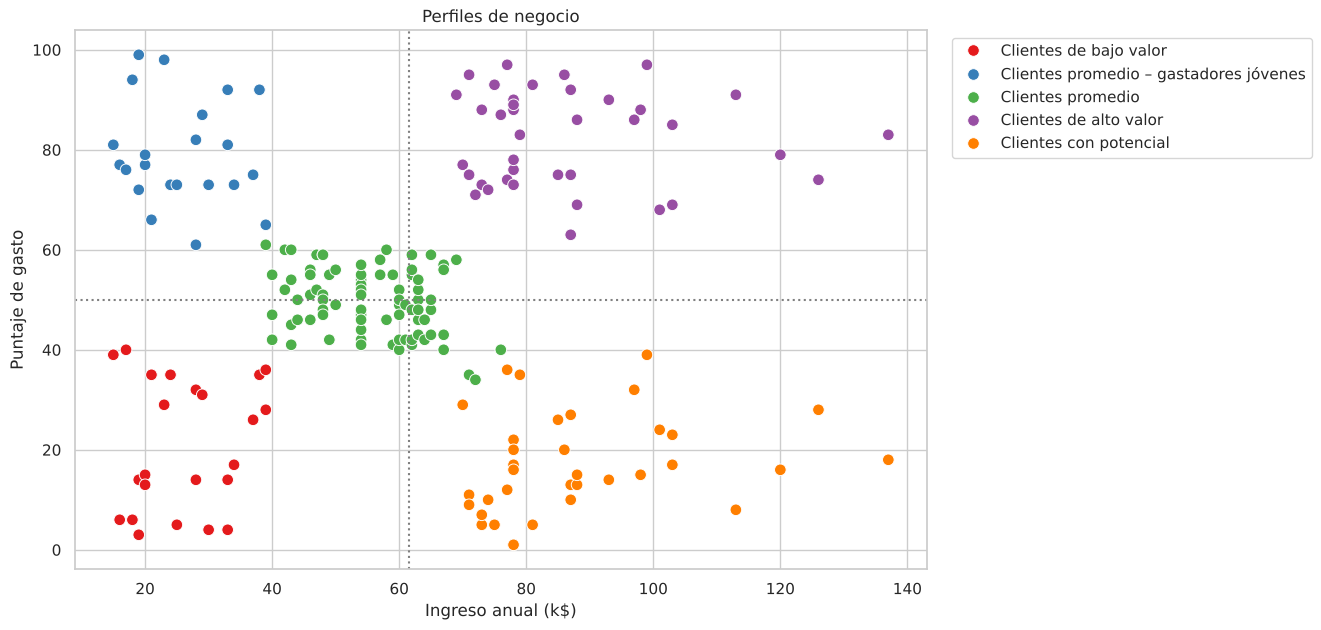

In [22]:
plt.figure(figsize=(11, 7))
sns.scatterplot(data=df, x="Ingreso_Anual_k", y="Puntaje_Gasto", hue="Perfil", s=70, palette="Set1")
plt.axvline(ing_med, color="gray", ls=":"); plt.axhline(gas_med, color="gray", ls=":")
plt.title("Perfiles de negocio")
plt.xlabel("Ingreso anual (k$)"); plt.ylabel("Puntaje de gasto")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

### Clasificación de perfiles

| Perfil | Centroide | Justificación |
|---|---|---|
| **Clientes de alto valor** | ingreso ≈ 87 k$, gasto ≈ 82 | Tienen capacidad y la usan: son los que más ingresos generan. |
| **Clientes promedio** | ingreso ≈ 55 k$, gasto ≈ 50 | Comportamiento estándar; la base estable del negocio. |
| **Clientes promedio – gastadores jóvenes** | ingreso ≈ 26 k$, gasto ≈ 79 | Gastan mucho para su ingreso; valor medio por su volumen limitado de compra, muy receptivos. Se agrupan con los promedio porque su valor monetario real está limitado por el ingreso. |
| **Clientes con potencial** | ingreso ≈ 88 k$, gasto ≈ 17 | Tienen alto poder adquisitivo pero casi no compran: la brecha entre lo que podrían gastar y lo que gastan es la mayor. |
| **Clientes de bajo valor** | ingreso ≈ 26 k$, gasto ≈ 21 | Poca capacidad y poco gasto. |

Como K = 5 y se piden 4 perfiles, el quinto grupo (ingreso bajo, gasto alto) se trata como una variante del perfil promedio con una estrategia propia.

### Preguntas – Parte 6

**¿Qué estrategias de marketing se podrían aplicar a cada grupo?**

- **Alto valor – retener y fidelizar:** programa de lealtad premium (niveles VIP, beneficios exclusivos), atención personalizada, preventas y lanzamientos anticipados, productos de gama alta y venta cruzada (*cross-selling*). El objetivo es evitar que se vayan a la competencia: perderlos es lo más costoso.
- **Promedio – aumentar frecuencia y ticket:** promociones por volumen (2×1, combos), cupones por recurrencia, puntos acumulables, comunicación periódica por correo/app y *up-selling* gradual. Al ser el 40 % de la base, pequeños aumentos de gasto tienen gran impacto total.
- **Promedio – gastadores jóvenes:** marketing en redes sociales e influenciadores, tendencias y lanzamientos, descuentos estudiantiles, opciones de pago a cuotas o "compra ahora, paga después" (con responsabilidad), y gamificación. Buscar fidelizarlos ahora, pues su ingreso probablemente crecerá con los años.
- **Con potencial – activar:** investigar por qué no compran (encuestas, análisis de experiencia), ofertas de alta calidad y valor percibido en lugar de descuentos masivos, experiencias exclusivas, asesoría personalizada (*personal shopper*), conveniencia (envío a domicilio, compra online) y campañas dirigidas por su edad (~41 años): hogar, familia, bienestar.
- **Bajo valor – eficiencia:** comunicación masiva de bajo costo, ofertas en productos básicos y temporadas de descuento, marcas propias. No invertir mucho presupuesto de adquisición; mantenerlos con acciones económicas.

**¿Qué segmento representa mayor oportunidad de crecimiento?**

Los **clientes con potencial** (ingreso alto, gasto bajo; ≈ 35 clientes, 17.5 %). Tienen prácticamente el mismo ingreso que el segmento de alto valor (≈ 88 k$ vs. 87 k$) pero gastan casi 5 veces menos (17 vs. 82). Esa brecha es dinero disponible que hoy se va a otros lugares: si una campaña consigue que su puntaje de gasto suba solo hasta el nivel promedio (~50), el aumento por cliente sería mayor que el de cualquier otro grupo. Además no hace falta adquirirlos, ya están en la base de clientes.

Como oportunidad secundaria, los **clientes promedio** por su tamaño (el 40 % de la base) y los **gastadores jóvenes** como inversión a largo plazo.

---
## Parte 7 – Despliegue con Streamlit

Se guardan el modelo, el escalador y los datos segmentados para que la aplicación `app.py` los use.

In [23]:
artefactos = {
    "modelo": kmeans,
    "scaler": scaler,
    "features": FEATURES,
    "perfiles": PERFILES,
    "inercias": inercias,
    "siluetas": siluetas,
}
joblib.dump(artefactos, "modelo_kmeans.pkl")
df.to_csv("clientes_segmentados.csv", index=False)
print("Guardado: modelo_kmeans.pkl y clientes_segmentados.csv")

Guardado: modelo_kmeans.pkl y clientes_segmentados.csv


In [24]:
# Prueba de clasificación de un cliente nuevo (lo mismo que hará la app)
nuevo = pd.DataFrame([[90, 15]], columns=FEATURES)   # ingreso 90 k$, gasto 15
c = int(kmeans.predict(scaler.transform(nuevo))[0])
print(f"Cliente nuevo -> Cluster {c}: {PERFILES[c]}")

Cliente nuevo -> Cluster 3: Clientes con potencial


La aplicación (`app.py`) permite:

1. **Visualizar el método del codo** (y la silueta) con un K de referencia ajustable.
2. **Mostrar los clusters** generados con sus centroides y una tabla resumen por perfil.
3. **Ingresar un nuevo cliente** (ingreso anual y puntaje de gasto; la edad y el género son informativos).
4. **Clasificarlo automáticamente**: se escala con el mismo `StandardScaler`, se predice el cluster, se muestra su perfil, la estrategia recomendada y su ubicación en el gráfico.

**Para ejecutarla** (en la misma carpeta donde están `app.py`, `Mall_Customers.xls` y, opcionalmente, `modelo_kmeans.pkl`):

```bash
pip install -r requirements.txt
streamlit run app.py
```

Si `modelo_kmeans.pkl` no existe, la app entrena el modelo al iniciar a partir del archivo de datos.